<a href="https://colab.research.google.com/github/Abhibanda09/bank-marketing-ml-prediction/blob/main/Bank_Marketing_Prediction_AlgorithmShowdown.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Project Description

This project compares multiple supervised classification algorithms on the UCI Bank Marketing dataset. The dataset contains information about clients contacted during bank marketing campaigns. The task is to predict whether a client subscribed to a term deposit (`yes` or `no`).

The project follows an end-to-end workflow: dataset understanding, data-quality checks, exploratory analysis, preprocessing, feature engineering, model training, cross-validation, model comparison, held-out evaluation and interpretation. The study also examines how the choice of evaluation metric affects model selection when the target classes are imbalanced.

## Problem Statement and Objectives

### Problem statement
A bank conducts marketing campaigns to promote term-deposit subscriptions. Contacting every customer is costly, and not every customer subscribes. The project investigates whether customer and campaign information available before a call can help classify the likelihood of subscription.

### Objectives
1. Understand the Bank Marketing dataset, its variables, target distribution and data-quality issues.
2. Explore relationships between customer characteristics and term-deposit subscription.
3. Prepare numerical and categorical features using a reproducible preprocessing pipeline.
4. Train and compare seven classification algorithms using a consistent train/test split and stratified cross-validation.
5. Evaluate the selected model using accuracy, precision, recall, F1-score, confusion matrix and additional ranking metrics where useful.
6. Interpret the results, identify limitations and discuss how predictive scores could support more focused marketing decisions.

### Scope and prediction timing
The primary prediction is intended to be made **before a marketing call**. Therefore, `duration` (call duration, known only after the call) and `campaign` (which can include the current contact) are excluded from the predictive features to reduce information leakage.

## Dataset Source and Description

**Dataset:** Bank Marketing (UCI Machine Learning Repository)  
**Source:** https://archive.ics.uci.edu/dataset/222/bank+marketing  
**Python access:** `ucimlrepo` package, dataset ID `222` (see the data-import section).

The dataset describes direct marketing campaigns of a Portuguese banking institution. The target variable is `y`, renamed in this notebook to `deposit`, and indicates whether the client subscribed to a term deposit.

The dataset includes customer attributes (for example, age, job, marital status, education and balance), contact information (for example, contact type and month), and previous campaign information (for example, `pdays`, `previous` and `poutcome`).

**Dataset limitations:** The data comes from a particular bank and campaign context; patterns may not generalize to other banks, countries or time periods. The observed association between a feature and subscription does not establish causation. The exact number of rows and columns is printed during data import so the report uses the dimensions of the retrieved dataset rather than an assumed value.

### Dataset Summary: Bank Marketing

#### 1. Overview
This dataset contains direct-marketing campaign records from a Portuguese banking institution. The classification target is whether a client subscribed to a term deposit (`y`, renamed to `deposit` in this notebook; values `yes` and `no`).

#### 2. Shape and structure
The UCI Bank Marketing (`bank-full`) dataset is expected to contain 45,211 records, 16 predictor columns and one target column. The notebook prints the actual shape, data types, duplicate count and value counts after loading; use those live outputs if the downloaded source version differs.

#### 3. Important data-quality details
Several categorical columns use the literal string `unknown` as a category. These are not necessarily null/`NaN` values, so they should not be described as missing-value counts. In the common `bank-full` file, `unknown` occurs frequently in `job`, `education`, `contact` and especially `poutcome`.

| Column | Meaning / treatment |
|---|---|
| `age` | Client age |
| `job`, `marital`, `education` | Customer profile categories; retain `unknown` as an explicit category |
| `default`, `housing`, `loan` | Credit/default and loan indicators |
| `balance` | Average yearly account balance |
| `day` | Day of the month of the last contact (renamed from source column `day_of_week`) |
| `month` | Month of the last contact |
| `duration` | Call duration in seconds; known only after the call, so exclude from a pre-call prediction model |
| `campaign` | Number of contacts during the current campaign |
| `pdays` | Days since a previous contact; `-1` is a sentinel meaning no previous contact |
| `previous` | Number of contacts before the current campaign |
| `poutcome` | Outcome of a previous campaign; `unknown` is retained as a category |
| `deposit` | Target: `yes` or `no` |

#### 4. Key observations
- Do not interpret `unknown` category values as numeric missing values. The preprocessing pipeline retains these categories through one-hot encoding.
- `pdays = -1` is a special sentinel, not a real negative number of days. The notebook creates a `previously_contacted` indicator and treats `-1` as missing for the numeric `pdays` feature.
- The target is imbalanced, so accuracy alone is insufficient for comparing classifiers.

## 1. Import required libraries
**What this code does:** imports the libraries used in the notebook and fixes a random seed (`RANDOM_STATE = 42`) so that splits and models give the same results each time you run them.

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import json
import joblib
import sklearn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from scipy import stats

from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_validate, GridSearchCV, cross_val_predict,
                                     cross_val_score)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report,
                             RocCurveDisplay, PrecisionRecallDisplay,
                             precision_recall_curve, brier_score_loss)
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import LinearSVC
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)

scikit-learn 1.6.1 | pandas 2.2.3 | numpy 2.4.6


**What the output tells you:** one line with the library versions. Write these down. Results can differ slightly between versions of scikit-learn, so your report should state them.

## 2. Dataset source and data import
**What this code does:** installs the helper packages, downloads the Bank Marketing dataset from the UCI repository (ID 222), joins the features and the target into one table, and renames two columns. The source column `day_of_week` actually holds the day of the month (1 to 31), so it is renamed to `day`.

In [ ]:
%pip -q install ucimlrepo plotly joblib

from ucimlrepo import fetch_ucirepo

bank = fetch_ucirepo(id=222)
df = pd.concat([bank.data.features, bank.data.targets], axis=1)
df = df.rename(columns={"y": "deposit", "day_of_week": "day"})
# The UCI loader returns missing categorical values as real NaN, not as the text "unknown".
# Convert them to an explicit "unknown" category so that (a) EDA counts them instead of
# silently dropping them and (b) the pipeline does not impute them with the most frequent value
# (which would, for example, merge "no previous campaign" into "previous campaign failed").
cat_in_df = [c for c in df.select_dtypes(exclude="number").columns if c != "deposit"]
missing_before = df[cat_in_df].isna().sum()
print("Missing categorical values converted to 'unknown':")
display(missing_before[missing_before > 0].to_frame("count"))
df[cat_in_df] = df[cat_in_df].fillna("unknown")

print("Shape (rows, columns):", df.shape)
df.head()

Missing categorical values converted to 'unknown':


,count
job,288
education,1857
contact,13020
poutcome,36959


Shape (rows, columns): (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


**What the output tells you:**
- The small table lists how many missing values were converted to the explicit category `unknown` (mainly `poutcome`, `contact`, `education` and `job`). The UCI loader supplies these as NaN, so this step is needed for the rest of the notebook to treat them as a category.
- The shape should be about **45,211 rows and 17 columns**: 16 predictors plus the target `deposit`.
- `head()` should show `deposit` as `yes` or `no`. If it shows `y` or numbers, the rename did not run.
- `day` should contain values from 1 to 31. This confirms it is the day of the month, not the day of the week.

## 3. Data understanding
**What this code does:** counts exact duplicate rows, shows each column's type, and gives summary statistics (count, mean, min, max, quartiles).

In [ ]:
# export data for manual assesment
with pd.ExcelWriter('bank_marketing.xlsx') as writer:
    df.to_excel(writer, index=False)

In [ ]:
print("Exact duplicate rows:", int(df.duplicated().sum()))
print()
display(df.dtypes.to_frame("dtype"))
display(df.describe(include="all").T)

Exact duplicate rows: 0



,dtype
age,int64
job,object
marital,object
education,object
default,object
balance,int64
housing,object
loan,object
contact,object
day,int64


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,45211.0,NaN,NaN,NaN,40.93621,10.618762,18.0,33.0,39.0,48.0,95.0
job,45211,12,blue-collar,9732,NaN,NaN,NaN,NaN,NaN,NaN,NaN
marital,45211,3,married,27214,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education,45211,4,secondary,23202,NaN,NaN,NaN,NaN,NaN,NaN,NaN
default,45211,2,no,44396,NaN,NaN,NaN,NaN,NaN,NaN,NaN
balance,45211.0,NaN,NaN,NaN,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
housing,45211,2,yes,25130,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan,45211,2,no,37967,NaN,NaN,NaN,NaN,NaN,NaN,NaN
contact,45211,3,cellular,29285,NaN,NaN,NaN,NaN,NaN,NaN,NaN
day,45211.0,NaN,NaN,NaN,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0


**What the output tells you:**
- **Duplicates:** a small number is normal. The modelling step removes them, so the model does not see the same customer twice.
- **Dtypes:** numeric columns (`age`, `balance`, `day`, `duration`, `campaign`, `pdays`, `previous`) should be integers. Text columns (`job`, `marital`, and so on) should be `object`. A numeric column stored as text would signal a loading problem.
- **describe():** check `pdays`. Its minimum is `-1`, and this is a sentinel meaning "never contacted", not a real value. Its median is also `-1`, which shows that most customers were not contacted before. `balance` has a large maximum compared with its median, which signals outliers and skew.

### 3.1 Target Variable Distribution
**What this code does:** counts and plots how many customers subscribed (`yes`) and how many did not (`no`).

,count,percent
deposit,,
no,39922,88.3
yes,5289,11.7


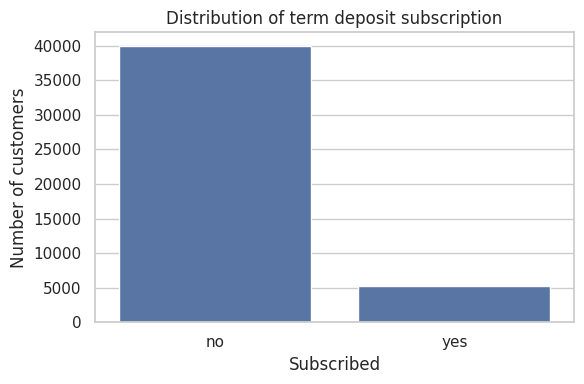

In [ ]:
counts = df["deposit"].value_counts()
pct = (counts / counts.sum() * 100).round(2)
display(pd.DataFrame({"count": counts, "percent": pct}))

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="deposit")
plt.title("Distribution of term deposit subscription")
plt.xlabel("Subscribed")
plt.ylabel("Number of customers")
plt.tight_layout()
plt.show()

**What the output tells you:**
- Roughly **88% `no` and 12% `yes`** (about 5,289 subscribers). This is an **imbalanced** target.
- Consequence: a model that always predicts `no` would be about 88% accurate and completely useless. This is why the notebook relies on recall, F1 and PR-AUC rather than accuracy.
- In your report, state the baseline: "A majority-class classifier would reach about 88% accuracy with zero recall."

### 3.2 Dataset quality and cleaning considerations
**What this code does:** counts true missing values (NaN) and counts the text value `unknown` in each categorical column.

The UCI dataset does not use blank cells. It writes `unknown` as a category. This check confirms that and shows where it occurs.

In [ ]:
print("Actual NaN count across all columns:", int(df.isna().sum().sum()))

unknown_counts = {
    col: int((df[col] == "unknown").sum())
    for col in df.select_dtypes(include="object").columns
    if (df[col] == "unknown").any()
}
display(pd.Series(unknown_counts, name="'unknown' count").sort_values(ascending=False).to_frame())

Actual NaN count across all columns: 0


,'unknown' count
poutcome,36959
contact,13020
education,1857
job,288


**What the output tells you:**
- **NaN count of 0** is expected here because Section 2 already converted the loader's NaN values into the category `unknown`. The imputers in the pipeline are therefore idle for these columns. They are kept as a safety net for new data.
- **`unknown` counts** show which fields are often not recorded. `poutcome` is usually the largest, because most customers had no earlier campaign. `contact` and `education` also have many `unknown` values.
- The notebook keeps `unknown` as its own category rather than treating it as missing. Your report should explain this choice: the value may carry information (for example, that a field was not recorded).

## 4. Exploratory Data Analysis (EDA)

### 4.1 Numeric feature distributions
**What this code does:** prints the skewness of each numeric column and draws a histogram with a density curve (KDE) for each one.

,skewness
previous,41.846
balance,8.360
campaign,4.899
duration,3.144
pdays,2.616
age,0.685
day,0.093


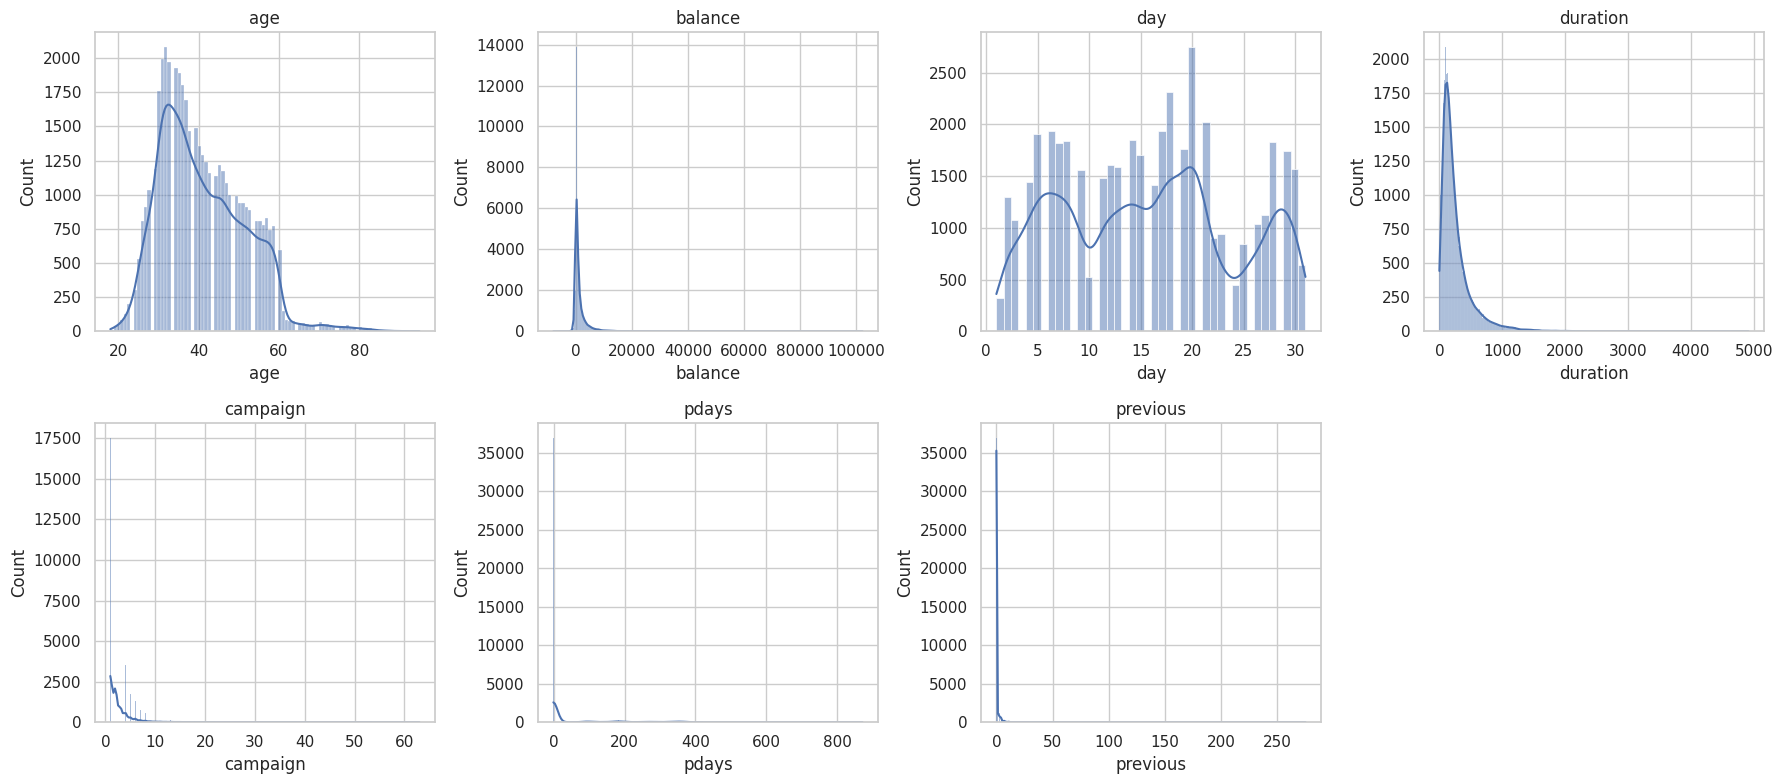

In [ ]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
skew = df[numeric_cols].skew().round(3).sort_values(ascending=False)
display(skew.to_frame("skewness"))

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.ravel()
for ax, col in zip(axes, numeric_cols):
    sns.histplot(df[col], kde=True, ax=ax)
    ax.set_title(col)
for ax in axes[len(numeric_cols):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

**What the output tells you:**
- **Skewness near 0** means a symmetric distribution, such as `day`.
- **Large positive skewness** (above 1) means a long right tail. `balance`, `campaign` and `previous` are expected to be strongly right-skewed. A few customers have very large balances or very many contacts.
- **Why this matters:** distance-based models (KNN, linear SVM, logistic regression) are sensitive to outliers. The pipeline uses `StandardScaler`, but it does not remove the skew. Mention this in your limitations if you do not transform the variables.
- `pdays` will show a large spike at `-1`. This is the "never contacted" group, not a real count of days.

### 4.2 Categorical feature exploration
**What this code does:** prints how often each category appears in each text column.

In [ ]:
cat_cols = df.select_dtypes(include="object").columns.tolist()
for col in cat_cols:
    print(f"\nFrequency counts for: {col}")
    display(df[col].value_counts().to_frame("count"))


Frequency counts for: job


,count
job,
blue-collar,9732
management,9458
technician,7597
admin.,5171
services,4154
retired,2264
self-employed,1579
entrepreneur,1487
unemployed,1303



Frequency counts for: marital


,count
marital,
married,27214
single,12790
divorced,5207



Frequency counts for: education


,count
education,
secondary,23202
tertiary,13301
primary,6851
unknown,1857


... (10 outputs left out)


Frequency counts for: poutcome


,count
poutcome,
unknown,36959
failure,4901
other,1840
success,1511



Frequency counts for: deposit


,count
deposit,
no,39922
yes,5289


**What the output tells you:**
- Look for **rare categories** (very small counts). A category seen only a few times gives an unreliable estimate, and it may be unseen in the test data.
- Look for **dominant categories**. For example, `poutcome = unknown` should be very large. A feature that is almost all one value carries little information.
- The notebook uses `OneHotEncoder(handle_unknown="ignore")`. This means a category that appears only in new data is ignored instead of crashing the model. Section 15.1 tests this.

### 4.3 Bivariate analysis and correlation
**What this code does:** computes Pearson correlations between numeric features and the target (encoded `yes` = 1, `no` = 0), then draws them as a heatmap.

Two adjustments make the correlations meaningful. `pdays = -1` is replaced with NaN, and a `previously_contacted` flag is added so that the "never contacted" status is kept.

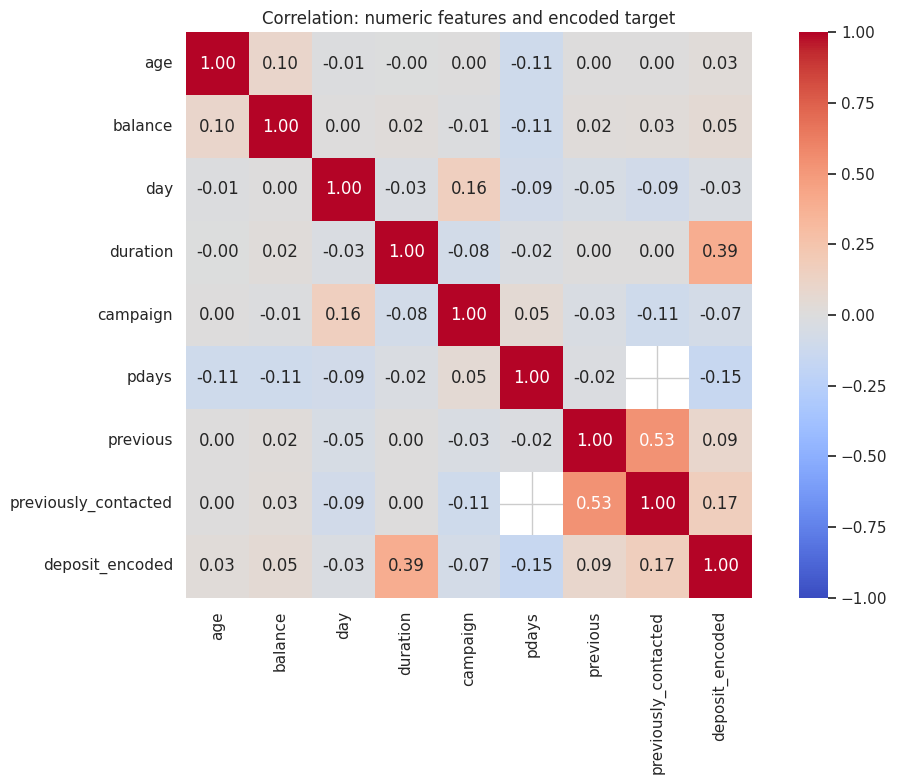

In [ ]:
corr = df.select_dtypes(include=np.number).copy()
corr["previously_contacted"] = (corr["pdays"] != -1).astype(int)
corr["pdays"] = corr["pdays"].replace(-1, np.nan)
corr["deposit_encoded"] = (df["deposit"] == "yes").astype(int)

matrix = corr.corr()
plt.figure(figsize=(11, 8))
sns.heatmap(matrix, annot=True, fmt=".2f", cmap="coolwarm",
            center=0, vmin=-1, vmax=1, square=True)
plt.title("Correlation: numeric features and encoded target")
plt.tight_layout()
plt.show()

**What the output tells you:**
- Look at the **`deposit_encoded`** row or column. Correlations with the target are usually small (most below 0.3 in absolute value). Weak linear correlation does not mean a feature is useless, because the models can capture non-linear effects.
- Look at **pairs of features** with high correlation (above about 0.7). Strongly correlated predictors can make a linear model's coefficients unstable. In this dataset most pairs are weakly correlated, so multicollinearity is not a major concern.
- `previously_contacted` and `pdays` are strongly related by design. Their correlation is high, and that is expected.
- **Caution:** Pearson correlation measures linear association only, and it does not show cause.

### 4.4 Target-focused analysis: subscription rate
**What this code does:** for each categorical feature, computes the percentage of customers who subscribed within each category, sorted from highest to lowest. This is the most business-relevant EDA step.

In [ ]:
for col in ["job", "marital", "education", "housing", "loan", "contact", "poutcome", "month"]:
    rate = (df.groupby(col)["deposit"]
              .apply(lambda s: (s == "yes").mean() * 100)
              .sort_values(ascending=False)
              .round(1))
    print(f"\nSubscription rate (%) by {col}")
    display(rate.to_frame("subscription_rate_%"))


Subscription rate (%) by job


,subscription_rate_%
job,
student,28.7
retired,22.8
unemployed,15.5
management,13.8
admin.,12.2
self-employed,11.8
unknown,11.8
technician,11.1
services,8.9



Subscription rate (%) by marital


,subscription_rate_%
marital,
single,14.9
divorced,11.9
married,10.1



Subscription rate (%) by education


,subscription_rate_%
education,
tertiary,15.0
unknown,13.6
secondary,10.6
primary,8.6


... (6 outputs left out)


Subscription rate (%) by poutcome


,subscription_rate_%
poutcome,
success,64.7
other,16.7
failure,12.6
unknown,9.2



Subscription rate (%) by month


,subscription_rate_%
month,
mar,52.0
dec,46.7
sep,46.5
oct,43.8
apr,19.7
feb,16.6
aug,11.0
jun,10.2
nov,10.2


**What the output tells you:**
- **Large gaps between categories** point to useful predictors. For example, a `poutcome` value of `success` (a previous campaign succeeded) usually has a much higher rate than `unknown`.
- **`housing` and `loan`:** customers with a housing or personal loan usually subscribe less often. Check whether the gap is large.
- **`month`:** some months have very few contacts. Their rates come from small samples and should not be over-interpreted.
- **Rule of thumb for your report:** a category with fewer than about 100 customers should be called "too small to conclude".
- These are historical associations. They describe the past campaign and do not prove that a feature causes subscription.

### 4.5 Hypothesis Testing
**What this code does:** tests whether the average account balance differs between subscribers and non-subscribers.

- **H0 (null):** the balance distributions are the same for both groups.
- **Welch t-test:** compares means without assuming equal variances.
- **Mann-Whitney U:** compares distributions without assuming normality. This is safer here because `balance` is heavily skewed.
- **Cohen's d:** measures the size of the difference, independent of sample size.

In [ ]:
yes_bal = df.loc[df["deposit"] == "yes", "balance"].dropna()
no_bal = df.loc[df["deposit"] == "no", "balance"].dropna()

welch = stats.ttest_ind(yes_bal, no_bal, equal_var=False)
mann = stats.mannwhitneyu(yes_bal, no_bal, alternative="two-sided")

pooled_sd = np.sqrt(((len(yes_bal) - 1) * yes_bal.var(ddof=1) +
                     (len(no_bal) - 1) * no_bal.var(ddof=1)) /
                    (len(yes_bal) + len(no_bal) - 2))
cohens_d = (yes_bal.mean() - no_bal.mean()) / pooled_sd

results = pd.DataFrame([
    {"Test": "Welch t-test", "Statistic": welch.statistic, "p-value": welch.pvalue},
    {"Test": "Mann-Whitney U", "Statistic": mann.statistic, "p-value": mann.pvalue},
])
display(results.round(6))
print("Median balance, subscribers:    ", yes_bal.median())
print("Median balance, non-subscribers:", no_bal.median())
print("Cohen's d:", round(cohens_d, 4))
print("Welch decision:", "reject H0" if welch.pvalue < 0.05 else "fail to reject H0")
print("Mann-Whitney decision:", "reject H0" if mann.pvalue < 0.05 else "fail to reject H0")

,Test,Statistic,p-value
0,Welch t-test,9.933545e+00,0.0
1,Mann-Whitney U,1.245900e+08,0.0


Median balance, subscribers:     733.0
Median balance, non-subscribers: 417.0
Cohen's d: 0.1646
Welch decision: reject H0
Mann-Whitney decision: reject H0


**What the output tells you:**
- **p-value:** with a large sample, almost any tiny difference is "significant". A p-value below 0.05 only says the difference is unlikely to be pure chance.
- **Cohen's d:** the real question is the size. Roughly 0.2 is small, 0.5 medium and 0.8 large. A d near 0.1 is practically negligible even if p is tiny.
- **Compare the medians with the means:** if the mean is much larger than the median, the mean is pulled up by a few very rich customers. This supports using the rank-based Mann-Whitney test.
- **Report wording:** "The difference is statistically significant (p < 0.05), but the effect size is small (d = …)." This is more honest than "balance determines subscription".

### 4.6 Interactive 3D and 4D visualisations using Plotly

The following charts provide interactive views of customer age, account balance, campaign-contact count and subscription outcome. A sample is used to keep the notebook responsive in Google Colab. These are exploratory visualisations, not model inputs or evidence of causation.

In [ ]:
# Interactive 3D and 4D visualisations
%pip -q install plotly

import plotly.express as px

plot_df = df.copy()
plot_df["deposit"] = plot_df["deposit"].astype(str).str.strip().str.lower()
plot_sample = plot_df.sample(n=min(3000, len(plot_df)), random_state=RANDOM_STATE)

fig_3d = px.scatter_3d(
    plot_sample, x="age", y="balance", z="campaign",
    color="deposit",
    hover_data=["job", "education", "housing", "loan"],
    title="3D View: Age, Account Balance and Campaign Contacts",
    opacity=0.65
)
fig_3d.update_layout(
    scene=dict(xaxis_title="Customer age",
               yaxis_title="Account balance",
               zaxis_title="Campaign contacts"),
    legend_title="Term deposit"
)
fig_3d.show()

fig_4d = px.scatter_3d(
    plot_sample, x="age", y="balance", z="campaign",
    color="deposit", symbol="housing",
    hover_data=["job", "marital", "education", "loan", "poutcome"],
    title="4D View: Customer Profile and Subscription Outcome",
    opacity=0.65
)
fig_4d.update_layout(
    scene=dict(xaxis_title="Customer age",
               yaxis_title="Account balance",
               zaxis_title="Campaign contacts"),
    legend_title="Deposit / Housing"
)
fig_4d.show()

### 4.7 Interactive 2D EDA dashboard

These additional interactive charts help inspect differences in age, balance and subscription rates across customer groups. They complement, rather than replace, the static EDA plots above.

In [ ]:
# Interactive age and balance distributions by subscription outcome
fig_age = px.histogram(
    plot_df, x="age", color="deposit", barmode="overlay",
    marginal="box", opacity=0.65, nbins=40,
    title="Interactive Age Distribution by Deposit Outcome",
    labels={"age": "Customer age", "deposit": "Subscribed"}
)
fig_age.show()

fig_balance = px.box(
    plot_df, x="deposit", y="balance", color="deposit",
    points="outliers",
    title="Account Balance by Deposit Outcome",
    labels={"deposit": "Subscribed", "balance": "Account balance"}
)
fig_balance.show()

job_rate = (
    plot_df.assign(subscribed=(plot_df["deposit"] == "yes").astype(int))
    .groupby("job", as_index=False)
    .agg(subscription_rate=("subscribed", "mean"),
         customers=("subscribed", "size"))
    .sort_values("subscription_rate", ascending=True)
)
job_rate["subscription_rate_pct"] = job_rate["subscription_rate"] * 100
fig_job = px.bar(
    job_rate, x="subscription_rate_pct", y="job", orientation="h",
    color="subscription_rate_pct",
    title="Term-Deposit Subscription Rate by Job",
    labels={"subscription_rate_pct": "Subscribers (%)", "job": "Job category"},
    hover_data=["customers"]
)
fig_job.show()

fig_age_balance = px.scatter(
    plot_sample, x="age", y="balance", color="deposit",
    size="campaign", size_max=12, opacity=0.6,
    hover_data=["job", "education", "housing", "loan"],
    title="Age vs Account Balance by Subscription Outcome"
)
fig_age_balance.show()

## 5. Data cleaning and preprocessing for machine learning
**What this code does:** defines `prepare_features`, the single function that turns a raw customer table into model inputs. It does three things:
1. Drops the columns that are not known before the call: `deposit` (the target), `duration` (known only after the call) and `campaign` (includes the current contact).
2. Adds a `previously_contacted` flag.
3. Replaces the sentinel `pdays = -1` with NaN, so it is not read as a real number of days.

The same function is used for training and for new customers. Using one function for both prevents the most common production bug: training and serving using different preprocessing.

In [ ]:
EXCLUDED_COLUMNS = ["deposit", "duration", "campaign"]

def prepare_features(frame: pd.DataFrame) -> pd.DataFrame:
    """Return the pre-call predictor matrix. Used for training and for new customers."""
    out = frame.drop(columns=[c for c in EXCLUDED_COLUMNS if c in frame.columns]).copy()
    if "pdays" in out.columns:
        out["previously_contacted"] = (out["pdays"] != -1).astype(int)
        out["pdays"] = out["pdays"].replace(-1, np.nan)
    return out

data = df.drop_duplicates().reset_index(drop=True)
y = data["deposit"].map({"no": 0, "yes": 1})
assert y.notna().all(), "Unexpected target labels"

X = prepare_features(data)
RAW_COLUMNS = [c for c in data.columns if c not in EXCLUDED_COLUMNS]
numeric_features = X.select_dtypes(include="number").columns.tolist()
categorical_features = X.select_dtypes(exclude="number").columns.tolist()

print("Modelling rows:", len(X))
print("Predictor columns:", X.shape[1])
print("Numeric:", numeric_features)
print("Categorical:", categorical_features)
print("Excluded:", EXCLUDED_COLUMNS)

Modelling rows: 45211
Predictor columns: 15
Numeric: ['age', 'balance', 'day', 'pdays', 'previous', 'previously_contacted']
Categorical: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']
Excluded: ['deposit', 'duration', 'campaign']


**What the output tells you:**
- **Modelling rows** should be the original count minus the duplicates removed in Section 3.
- **Predictor columns** should be 14 raw columns plus the `previously_contacted` flag, which gives 15 predictors. Check that `duration` and `campaign` are **not** in either list.
- **Numeric list** should include `pdays` and `previously_contacted`. **Categorical list** should include `job`, `marital`, `education`, `default`, `housing`, `loan`, `contact`, `month` and `poutcome`.
- If `duration` appears in these lists, the model would see the call outcome and its scores would be unrealistically high. This is the most important check in the notebook.

## 6. Train-test split
**What this code does:** sets aside 20% of the customers as a test set that is used only once at the end. `stratify=y` keeps the same subscription rate in both sets, which matters because the target is imbalanced.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Training rows:", len(X_train), "| Test rows:", len(X_test))
print("\nTraining class proportions:")
display(y_train.value_counts(normalize=True).rename("proportion").to_frame())
print("Test class proportions:")
display(y_test.value_counts(normalize=True).rename("proportion").to_frame())

Training rows: 36168 | Test rows: 9043

Training class proportions:


,proportion
deposit,
0,0.883018
1,0.116982


Test class proportions:


,proportion
deposit,
0,0.883003
1,0.116997


**What the output tells you:**
- Roughly **80% training and 20% test**.
- The two class proportions should be almost identical (about 88/12 in both). If they differ noticeably, stratification failed.
- This split is random. A real bank deployment would split by time (train on earlier campaigns, test on later ones). Section 17 discusses this.

### 6.1 Exploratory PCA and K-Means (Not Used for Prediction)
**What this code does:**
- **PCA** compresses all predictors into two axes (PC1 and PC2) so the data can be plotted. It shows how much of the total variation each axis keeps.
- **K-Means** groups customers into two clusters without looking at the target. The target is only used afterwards to describe each cluster.

These results are exploratory. They are not used to train the classifiers, and the target does not influence the clustering.

Variance explained by PC1 and PC2: [17.76 11.81] %


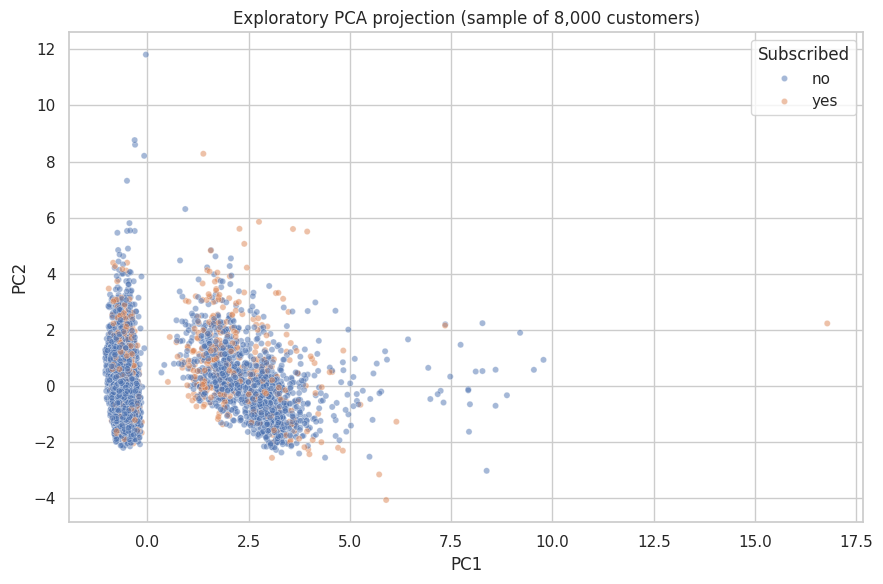

,customers,subscribers,rate,rate_%
cluster,,,,
0,8257,1905,0.230713,23.07
1,36954,3384,0.091573,9.16


Cluster numbers are arbitrary labels, not predicted classes.


In [ ]:
prep_for_pca = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                      ("scaler", StandardScaler())]), numeric_features),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore"))]), categorical_features),
], sparse_threshold=0.0)

X_dense = prep_for_pca.fit_transform(X)
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_dense)
print("Variance explained by PC1 and PC2:", np.round(pca.explained_variance_ratio_ * 100, 2), "%")

plot_df = pd.DataFrame({"PC1": X_pca[:, 0], "PC2": X_pca[:, 1], "Subscribed": data["deposit"].values})
sample = plot_df.sample(min(8000, len(plot_df)), random_state=RANDOM_STATE)
plt.figure(figsize=(9, 6))
sns.scatterplot(data=sample, x="PC1", y="PC2", hue="Subscribed", alpha=0.5, s=20)
plt.title("Exploratory PCA projection (sample of 8,000 customers)")
plt.tight_layout()
plt.show()

kmeans = KMeans(n_clusters=2, random_state=RANDOM_STATE, n_init=10)
clusters = kmeans.fit_predict(X_dense)
summary = (pd.DataFrame({"cluster": clusters, "subscribed": (data["deposit"] == "yes").astype(int)})
             .groupby("cluster")["subscribed"].agg(customers="size", subscribers="sum", rate="mean"))
summary["rate_%"] = (summary["rate"] * 100).round(2)
display(summary)
print("Cluster numbers are arbitrary labels, not predicted classes.")

**What the output tells you:**
- **Variance explained:** if PC1 and PC2 together explain only about 20 to 30%, the two-dimensional plot hides much of the structure. Say so in your report, and do not treat the picture as the full story.
- **PCA plot:** heavy overlap between `yes` and `no` is normal for this kind of data. It means no simple two-dimensional separation exists, which is why a classifier is needed.
- **K-Means table:** if one cluster has a noticeably higher `rate_%`, it suggests a customer segment worth targeting. Check whether the difference is large enough to matter.
- The cluster IDs (0 and 1) are arbitrary. Only the rates are meaningful.

## 7. Preprocessing pipeline and classification algorithms
**What this code does:** builds the preprocessing steps and the seven models, each wrapped in a `Pipeline`.

- **Numeric branch:** fill missing values with the median, then standardise (mean 0, standard deviation 1).
- **Categorical branch:** fill missing values with the most frequent value, then one-hot encode (one yes/no column per category).
- **Two preprocessors:** Gradient Boosting and Naive Bayes need dense arrays, so they get a version that does not return sparse matrices.

**Class imbalance, stated openly:** Logistic Regression, Decision Tree, Random Forest and Linear SVM use `class_weight="balanced"`. Gradient Boosting, KNN and Naive Bayes have no equivalent option in this setup, so they see the raw 88/12 split. This makes the comparison less controlled because the models are not trained under identical imbalance treatments. Section 8.1 reduces this problem by giving every model its own tuned decision threshold, and PR-AUC is threshold-independent. Differences in training-time class weighting still remain, so your report should disclose this limitation.

### 7.1 Algorithms included in this study

The comparison uses **all seven algorithms**:

1. Logistic Regression
2. Decision Tree
3. Random Forest
4. Gradient Boosting
5. K-Nearest Neighbours (KNN)
6. Gaussian Naive Bayes
7. Linear Support Vector Machine (SVM)

All seven are evaluated using the same training partition and stratified five-fold cross-validation. The preprocessing is placed inside each model pipeline to avoid fitting transformations on validation folds. Class-imbalance handling differs by algorithm. Section 8.1 compares the models with a separately tuned threshold for each one, and the remaining training-setup difference is disclosed as a limitation.

In [ ]:
numeric_tf = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_tf = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("num", numeric_tf, numeric_features),
    ("cat", categorical_tf, categorical_features),
])
preprocessor_dense = ColumnTransformer([
    ("num", numeric_tf, numeric_features),
    ("cat", categorical_tf, categorical_features),
], sparse_threshold=0.0)

models = {
    "Logistic Regression": (preprocessor,
        LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE)),
    "Decision Tree": (preprocessor,
        DecisionTreeClassifier(max_depth=8, min_samples_leaf=10,
                               class_weight="balanced", random_state=RANDOM_STATE)),
    "Random Forest": (preprocessor,
        RandomForestClassifier(n_estimators=250, max_features="sqrt",
                               class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE)),
    "Gradient Boosting": (preprocessor_dense,
        GradientBoostingClassifier(n_estimators=100, learning_rate=0.08,
                                   max_depth=2, random_state=RANDOM_STATE)),
    "K-Nearest Neighbours": (preprocessor,
        KNeighborsClassifier(n_neighbors=7, weights="distance", n_jobs=-1)),
    "Gaussian Naive Bayes": (preprocessor_dense,
        GaussianNB()),
    "Linear SVM": (preprocessor,
        LinearSVC(C=1.0, class_weight="balanced", max_iter=5000, random_state=RANDOM_STATE)),
}

pipelines = {name: Pipeline([("preprocessing", prep), ("classifier", clf)])
             for name, (prep, clf) in models.items()}

for name, pipe in pipelines.items():
    print(f"{name:22s} -> {pipe.steps[-1][1].__class__.__name__}")

Logistic Regression    -> LogisticRegression
Decision Tree          -> DecisionTreeClassifier
Random Forest          -> RandomForestClassifier
Gradient Boosting      -> GradientBoostingClassifier
K-Nearest Neighbours   -> KNeighborsClassifier
Gaussian Naive Bayes   -> GaussianNB
Linear SVM             -> LinearSVC


**What the output tells you:**
- Seven lines, one per model, each ending in its classifier class name. Check that the names match the list in your report.
- No error means the preprocessing matches the columns. If you see an error about a missing column, `numeric_features` or `categorical_features` is wrong.
- This cell only builds the objects. It does not train anything yet.

## 8. Cross-validation and model comparison
**What this code does:** for each model, trains on 4/5 of the training data and tests on the remaining 1/5, repeating five times so that every customer is used for testing once. Preprocessing is refitted inside every fold, so no information leaks from the test fold into training.

This is a consistent evaluation step: all seven models use the same training data, cross-validation folds and scoring metrics. However, their class-imbalance treatments differ, so the comparison is not perfectly controlled.

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision",
}

rows = []
for name, pipe in pipelines.items():
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring,
                            n_jobs=1, error_score="raise")
    row = {"Algorithm": name}
    for metric in scoring:
        row[f"{metric} mean"] = scores[f"test_{metric}"].mean()
        row[f"{metric} std"] = scores[f"test_{metric}"].std()
    rows.append(row)

cv_results = (pd.DataFrame(rows)
                .sort_values("f1 mean", ascending=False)
                .reset_index(drop=True))
display(cv_results.round(4))

default_winner = cv_results.loc[0, "Algorithm"]
print("Top algorithm by mean CV F1 at the DEFAULT threshold:", default_winner)
print("(Section 8.1 repeats the comparison with a tuned threshold for every model.)")

,Algorithm,accuracy mean,accuracy std,precision mean,precision std,recall mean,recall std,f1 mean,f1 std,roc_auc mean,roc_auc std,pr_auc mean,pr_auc std
0,Decision Tree,0.8036,0.0251,0.3200,0.0353,0.5793,0.0219,0.4103,0.0244,0.7606,0.0056,0.3727,0.0087
1,Gaussian Naive Bayes,0.8347,0.0046,0.3422,0.0110,0.4467,0.0182,0.3873,0.0111,0.7361,0.0030,0.3314,0.0056
2,Linear SVM,0.7608,0.0074,0.2696,0.0071,0.6100,0.0095,0.3738,0.0065,0.7595,0.0033,0.3887,0.0085
3,Logistic Regression,0.7585,0.0070,0.2679,0.0064,0.6138,0.0104,0.3730,0.0060,0.7604,0.0033,0.3940,0.0075
4,Random Forest,0.8909,0.0007,0.5957,0.0068,0.2096,0.0114,0.3100,0.0127,0.7741,0.0047,0.4083,0.0152
5,K-Nearest Neighbours,0.8842,0.0019,0.5133,0.0216,0.1990,0.0113,0.2867,0.0139,0.7098,0.0067,0.3228,0.0131
6,Gradient Boosting,0.8932,0.0009,0.6668,0.0191,0.1751,0.0044,0.2774,0.0059,0.7821,0.0055,0.4239,0.0090


Top algorithm by mean CV F1 at the DEFAULT threshold: Decision Tree
(Section 8.1 repeats the comparison with a tuned threshold for every model.)


**What the output tells you:**
- **Mean vs std:** a model's mean is its average score. The std shows how much it varies across folds. If two models differ by less than about one std, their difference is **not reliable**, and you should say they are tied.
- **Read across the metrics, not just F1.**
  - High **recall** but low **precision**: the model contacts many people and many are not interested.
  - High **precision** but low **recall**: the model is selective but misses many likely subscribers.
  - **ROC-AUC** shows how well the model ranks customers overall. **PR-AUC** matters more here because the positive class is rare.
- A model with high ROC-AUC but low PR-AUC is good at ranking in general but weak on the rare positives.
- Write down the winner from **your** table. Do not copy a winner from another run.

### 8.1 Fairer comparison: a tuned threshold for every model
**Why this section exists:** Section 8 scores every model at its default cutoff. Four models use `class_weight="balanced"` and three do not, so at the default cutoff the unweighted models (Gradient Boosting, KNN, Naive Bayes) are penalised on recall and F1 for a reason unrelated to how well they rank customers.

**What this code does:** for every model it collects out-of-fold scores on the training data, finds the threshold that maximises F1 for that model, and reports the result next to the default-threshold F1 and the threshold-free PR-AUC and ROC-AUC. The algorithm selected for tuning and final evaluation is the one with the highest **best-threshold F1**.

**Caveat to state in your report:** the threshold is picked on the same out-of-fold scores it is reported on, so every number is slightly optimistic. The bias applies to all seven models alike, so the ranking is still fair. The test set is not used here.

In [ ]:
default_f1 = cv_results.set_index("Algorithm")["f1 mean"]
fair_rows = []
for name, pipe in pipelines.items():
    method = "predict_proba" if hasattr(pipe, "predict_proba") else "decision_function"
    s = cross_val_predict(pipe, X_train, y_train, cv=cv, method=method, n_jobs=1)
    s = s[:, 1] if s.ndim == 2 else np.asarray(s).ravel()
    p, r, t = precision_recall_curve(y_train, s)
    f1c = 2 * p[:-1] * r[:-1] / (p[:-1] + r[:-1] + 1e-12)
    k = int(np.nanargmax(f1c))
    fair_rows.append({
        "Algorithm": name,
        "F1 @ default threshold": default_f1[name],
        "Best-threshold F1 (OOF)": f1c[k],
        "Threshold": t[k],
        "Precision": p[k],
        "Recall": r[k],
        "PR-AUC (OOF)": average_precision_score(y_train, s),
        "ROC-AUC (OOF)": roc_auc_score(y_train, s),
    })

fair_results = (pd.DataFrame(fair_rows)
                  .sort_values("Best-threshold F1 (OOF)", ascending=False)
                  .reset_index(drop=True))
display(fair_results.round(4))

baseline_name = fair_results.loc[0, "Algorithm"]
pr_leader = fair_results.sort_values("PR-AUC (OOF)", ascending=False).iloc[0]["Algorithm"]
print("Winner at the default threshold (Section 8):     ", default_winner)
print("Winner with a tuned threshold per model (8.1):    ", baseline_name)
print("Best threshold-free ranking (highest PR-AUC):     ", pr_leader)
print("Selected for tuning and final evaluation:         ", baseline_name)

,Algorithm,F1 @ default threshold,Best-threshold F1 (OOF),Threshold,Precision,Recall,PR-AUC (OOF),ROC-AUC (OOF)
0,Gradient Boosting,0.2774,0.4782,0.1599,0.4561,0.5025,0.4216,0.7819
1,Decision Tree,0.4103,0.4443,0.7023,0.4329,0.4564,0.3860,0.7611
2,Random Forest,0.3100,0.4440,0.2440,0.4061,0.4897,0.4069,0.7741
3,Logistic Regression,0.3730,0.4329,0.6515,0.4527,0.4148,0.3930,0.7603
4,Linear SVM,0.3738,0.4305,0.1799,0.3977,0.4692,0.3877,0.7595
5,Gaussian Naive Bayes,0.3873,0.3993,1.0000,0.4757,0.3441,0.3308,0.7360
6,K-Nearest Neighbours,0.2867,0.3837,0.2671,0.3479,0.4278,0.3218,0.7098


Winner at the default threshold (Section 8):      Decision Tree
Winner with a tuned threshold per model (8.1):     Gradient Boosting
Best threshold-free ranking (highest PR-AUC):      Gradient Boosting
Selected for tuning and final evaluation:          Gradient Boosting


**What the output tells you:**
- Compare the two F1 columns. A model whose F1 jumps a lot once its threshold is tuned was being held back by the default cutoff, not by weak ranking. Expect this for the unweighted models.
- If the winner changed from Section 8, say so in your report: it shows that the original ranking partly reflected the class-weight differences rather than the algorithms themselves.
- The PR-AUC and ROC-AUC columns do not depend on any threshold. If the PR-AUC leader differs from the F1 winner, explain which metric matters more for the bank (finding most subscribers versus having a clean call list).
- Treat differences smaller than about one fold-to-fold standard deviation (see Section 8) as ties.

## 9. Model comparison visualisation
**What this code does:** draws the cross-validated F1 and PR-AUC with error bars (one standard deviation), so the ranking and its uncertainty appear together.

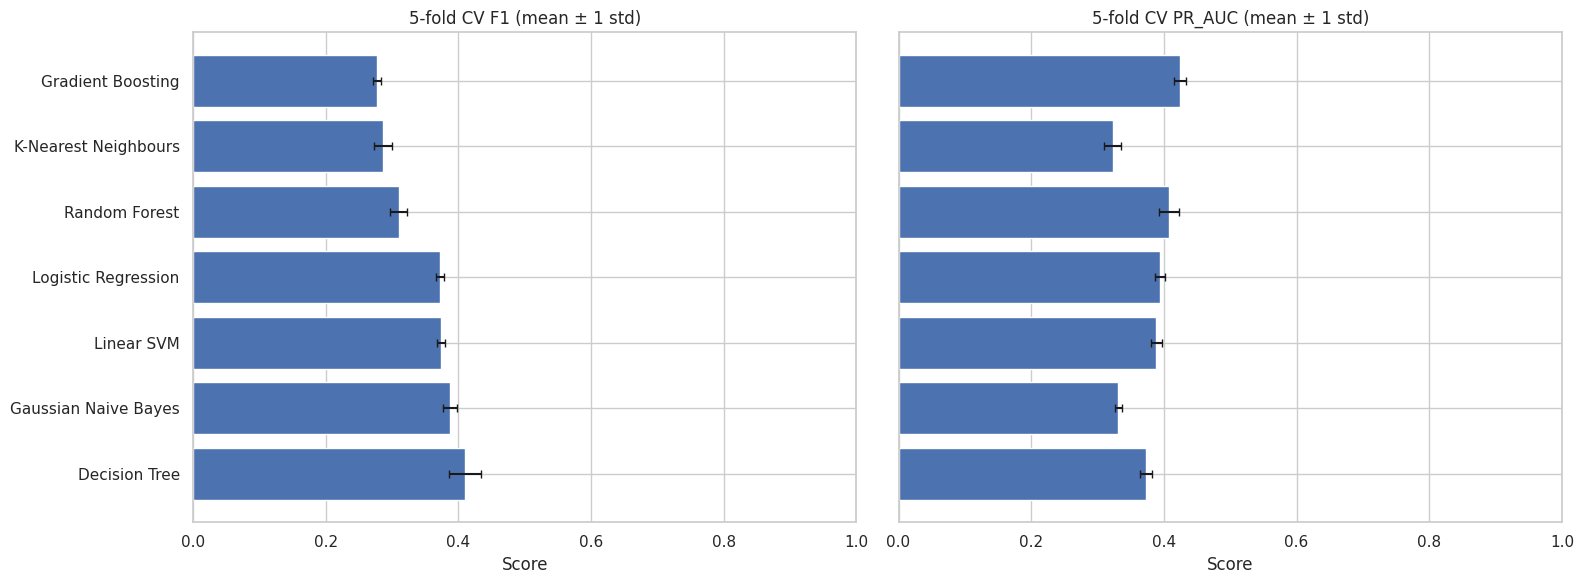

In [ ]:
plot_cv = cv_results.set_index("Algorithm")
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
for ax, metric in zip(axes, ["f1", "pr_auc"]):
    ax.barh(plot_cv.index, plot_cv[f"{metric} mean"], xerr=plot_cv[f"{metric} std"], capsize=3)
    ax.set_title(f"5-fold CV {metric.upper()} (mean ± 1 std)")
    ax.set_xlabel("Score")
    ax.set_xlim(0, 1)
plt.tight_layout()
plt.show()

## 9.1 Interactive Plotly model comparison dashboard

This dashboard uses the **five-fold cross-validation means and standard deviations** in `cv_results`. It compares all seven algorithms on four useful metrics. Hover over a bar to inspect its exact score and variability.

The dashboard is interactive: you can zoom, pan, hover, and use the legend to show or hide algorithms. It does not use the held-out test set to choose a model.

## 9.2 Model comparison radar chart

The radar chart compares the cross-validation metric profile of all seven algorithms. All metrics are on a 0–1 scale. A larger shape is not automatically a better business model: for this imbalanced dataset, pay particular attention to **F1 and PR-AUC**, and interpret them alongside the business cost of false positives and false negatives.


In [ ]:
# Interactive Plotly dashboard based on cross-validation results
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Metrics shown in the dashboard (all are cross-validation means)
dashboard_metrics = [
    ("accuracy", "Accuracy"),
    ("f1", "F1-score"),
    ("roc_auc", "ROC-AUC"),
    ("pr_auc", "PR-AUC"),
]

fig_dashboard = make_subplots(
    rows=2, cols=2,
    subplot_titles=[label for _, label in dashboard_metrics],
    horizontal_spacing=0.12,
    vertical_spacing=0.20
)

for i, (metric_key, metric_label) in enumerate(dashboard_metrics):
    row = (i // 2) + 1
    col = (i % 2) + 1
    mean_col = f"{metric_key} mean"
    std_col = f"{metric_key} std"

    fig_dashboard.add_trace(
        go.Bar(
            x=cv_results["Algorithm"],
            y=cv_results[mean_col],
            name=metric_label,
            error_y=dict(type="data", array=cv_results[std_col], visible=True),
            marker=dict(opacity=0.85),
            showlegend=False,
            customdata=cv_results[[std_col]].to_numpy(),
            hovertemplate=(
                "<b>%{x}</b><br>"
                + metric_label + ": %{y:.4f}<br>"
                + "CV standard deviation: %{customdata[0]:.4f}"
                + "<extra></extra>"
            ),
        ),
        row=row, col=col
    )
    fig_dashboard.update_yaxes(title_text="Mean CV score", range=[0, 1], row=row, col=col)
    fig_dashboard.update_xaxes(tickangle=-25, row=row, col=col)

fig_dashboard.update_layout(
    title=dict(text="Interactive Classification Model Dashboard", x=0.5),
    height=780,
    template="plotly_white",
    hovermode="closest",
    margin=dict(t=100, b=120, l=60, r=30),
)
fig_dashboard.show()

# Optional: a compact sortable comparison table using the same CV results
dashboard_table = cv_results[
    ["Algorithm", "accuracy mean", "precision mean", "recall mean",
     "f1 mean", "roc_auc mean", "pr_auc mean"]
].rename(columns={
    "accuracy mean": "Accuracy",
    "precision mean": "Precision",
    "recall mean": "Recall",
    "f1 mean": "F1",
    "roc_auc mean": "ROC-AUC",
    "pr_auc mean": "PR-AUC",
})
display(dashboard_table.round(4))


# Radar chart: compare the complete CV metric profile of each algorithm
radar_metrics = [
    ("accuracy mean", "Accuracy"),
    ("precision mean", "Precision"),
    ("recall mean", "Recall"),
    ("f1 mean", "F1"),
    ("roc_auc mean", "ROC-AUC"),
    ("pr_auc mean", "PR-AUC"),
]

fig_radar = go.Figure()

for _, model_row in cv_results.iterrows():
    values = [float(model_row[col]) for col, _ in radar_metrics]
    labels = [label for _, label in radar_metrics]

    # Close the polygon by repeating the first metric at the end
    fig_radar.add_trace(
        go.Scatterpolar(
            r=values + [values[0]],
            theta=labels + [labels[0]],
            name=model_row["Algorithm"],
            mode="lines+markers",
            fill="toself",
            opacity=0.55,
            hovertemplate="%{theta}: %{r:.4f}<extra>" + model_row["Algorithm"] + "</extra>",
        )
    )

fig_radar.update_layout(
    title=dict(text="Radar Chart: Cross-Validated Model Performance", x=0.5),
    template="plotly_white",
    polar=dict(
        radialaxis=dict(visible=True, range=[0, 1], tickformat=".1f")
    ),
    height=700,
    legend=dict(orientation="h", yanchor="top", y=-0.15, xanchor="center", x=0.5),
    margin=dict(t=90, b=140, l=70, r=70),
)
fig_radar.show()


,Algorithm,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Decision Tree,0.8036,0.3200,0.5793,0.4103,0.7606,0.3727
1,Gaussian Naive Bayes,0.8347,0.3422,0.4467,0.3873,0.7361,0.3314
2,Linear SVM,0.7608,0.2696,0.6100,0.3738,0.7595,0.3887
3,Logistic Regression,0.7585,0.2679,0.6138,0.3730,0.7604,0.3940
4,Random Forest,0.8909,0.5957,0.2096,0.3100,0.7741,0.4083
5,K-Nearest Neighbours,0.8842,0.5133,0.1990,0.2867,0.7098,0.3228
6,Gradient Boosting,0.8932,0.6668,0.1751,0.2774,0.7821,0.4239


**What the output tells you:**
- **Overlapping error bars** between the top models mean their performance is statistically close. Pick the simpler or faster model in that case, and say why.
- **A clear gap** that is larger than the error bars means a real difference.
- Notice whether the ranking by F1 is the same as the ranking by PR-AUC. If they disagree, state which metric matters more for the bank and why.

## 10. Hyperparameter tuning
**What this code does:** takes the top model from Section 8, tries a small set of settings for its key parameters, and keeps the setting with the best cross-validated PR-AUC (a threshold-free criterion, so the cutoff is handled separately in Section 13). The search uses only the training data.

Parameter names look like `classifier__C`. The part before the double underscore is the pipeline step name (`classifier`), and the part after is the parameter of that model.

In [ ]:
param_grids = {
    "Logistic Regression": {"classifier__C": [0.1, 1.0, 3.0]},
    "Decision Tree": {"classifier__max_depth": [5, 8, 12],
                      "classifier__min_samples_leaf": [5, 10, 20]},
    "Random Forest": {"classifier__n_estimators": [150, 250],
                      "classifier__max_depth": [None, 12, 20],
                      "classifier__min_samples_leaf": [1, 3]},
    "Gradient Boosting": {"classifier__n_estimators": [80, 120],
                          "classifier__learning_rate": [0.05, 0.08, 0.1],
                          "classifier__max_depth": [1, 2]},
    "K-Nearest Neighbours": {"classifier__n_neighbors": [5, 7, 11],
                             "classifier__weights": ["uniform", "distance"]},
    "Gaussian Naive Bayes": {"classifier__var_smoothing": [1e-9, 1e-8, 1e-7]},
    "Linear SVM": {"classifier__C": [0.1, 1.0, 3.0]},
}

grid = GridSearchCV(
    estimator=pipelines[baseline_name],
    param_grid=param_grids[baseline_name],
    scoring="average_precision",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE),
    refit=True,
)
grid.fit(X_train, y_train)

best_model = grid.best_estimator_
best_model_name = baseline_name
best_params = grid.best_params_
print("Tuned model:", best_model_name)
print("Best parameters:", best_params)
inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
untuned_ap = cross_val_score(pipelines[baseline_name], X_train, y_train,
                             cv=inner_cv, scoring="average_precision").mean()
print("Tuning CV PR-AUC, tuned settings:                  ", round(grid.best_score_, 4))
print("Tuning CV PR-AUC, default settings (same 3 folds): ", round(untuned_ap, 4))
print("Improvement from tuning:", round(grid.best_score_ - untuned_ap, 4))

Tuned model: Gradient Boosting
Best parameters: {'classifier__learning_rate': 0.1, 'classifier__max_depth': 2, 'classifier__n_estimators': 120}
Tuning CV PR-AUC, tuned settings:                   0.4302
Tuning CV PR-AUC, default settings (same 3 folds):  0.4239
Improvement from tuning: 0.0063


**What the output tells you:**
- **Best parameters:** a value at the edge of its range (for example `C = 3.0` or `max_depth = 12`, the largest values offered) suggests a wider search might help. Mention this as a limitation.
- **Tuned versus default PR-AUC:** both numbers use the **same three folds**, so they are directly comparable. If the improvement is close to zero, the default settings were already good. That is a useful finding in itself.
- Tuning uses PR-AUC rather than F1 because PR-AUC does not depend on the decision threshold. The threshold is chosen afterwards in Section 13.
- This search is deliberately small. Say so in your report.

## 11. Final model evaluation
**What this code does:** scores the tuned model on the test set, which has not been used for any decision so far. It reports the main metrics, a per-class report, and the confusion matrix.

The metrics use the default decision rule (probability ≥ 0.5, or the model's default boundary).

,Algorithm,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Gradient Boosting,0.5,0.8935,0.6667,0.1796,0.2829,0.7934,0.4372


              precision    recall  f1-score   support

          No       0.90      0.99      0.94      7985
         Yes       0.67      0.18      0.28      1058

    accuracy                           0.89      9043
   macro avg       0.78      0.58      0.61      9043
weighted avg       0.87      0.89      0.87      9043



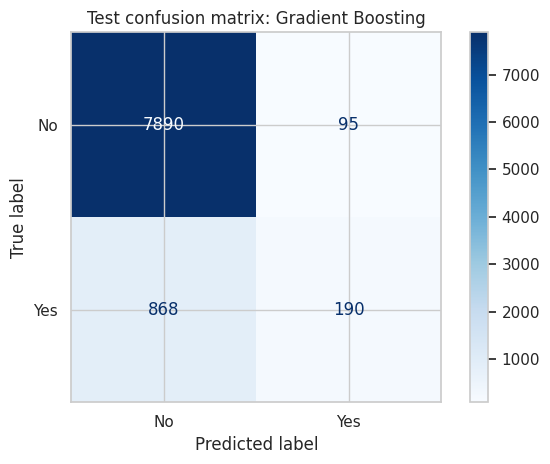

In [ ]:

# Final model evaluation using the default threshold

has_proba = hasattr(best_model, "predict_proba")
score_method = "predict_proba" if has_proba else "decision_function"

test_scores = (
    best_model.predict_proba(X_test)[:, 1]
    if has_proba
    else np.asarray(best_model.decision_function(X_test)).ravel()
)

# Standard decision threshold
default_threshold = 0.5 if has_proba else 0.0

# Explicitly apply the default threshold
test_pred = (test_scores >= default_threshold).astype(int)

final_metrics = pd.DataFrame([{
    "Algorithm": best_model_name,
    "Threshold": default_threshold,
    "Accuracy": accuracy_score(y_test, test_pred),
    "Precision": precision_score(y_test, test_pred, zero_division=0),
    "Recall": recall_score(y_test, test_pred, zero_division=0),
    "F1": f1_score(y_test, test_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, test_scores),
    "PR-AUC": average_precision_score(y_test, test_scores),
}])

display(final_metrics.round(4))

print(classification_report(
    y_test, test_pred,
    target_names=["No", "Yes"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test, test_pred,
    display_labels=["No", "Yes"],
    cmap="Blues",
    values_format="d"
)

plt.title(f"Test confusion matrix: {best_model_name}")
plt.tight_layout()
plt.show()


**What the output tells you:**
- **Compare with the CV numbers.** Test scores close to the CV scores mean the model generalises. A large drop (for example, F1 falling by more than about 0.05) suggests overfitting or an unlucky split.
- **Confusion matrix:**
  - Top-left: correctly predicted "no". Top-right: "yes" predicted but actually "no" (**false positives**, wasted calls).
  - Bottom-left: actual "yes" missed (**false negatives**, lost subscribers). Bottom-right: correctly predicted "yes".
  - For a bank, false negatives lose revenue and false positives cost call time. The right balance depends on the bank's priorities.
- **Classification report:** the "Yes" row is the one that matters. Its recall tells you what share of real subscribers you find.
- Do **not** return to tune the model after seeing these numbers. If you do, the test set is no longer a true test.

## 12. ROC and Precision-Recall curves
**What this code does:** plots the ROC curve (true positive rate against false positive rate) and the precision-recall curve for the tuned model, using the test set.

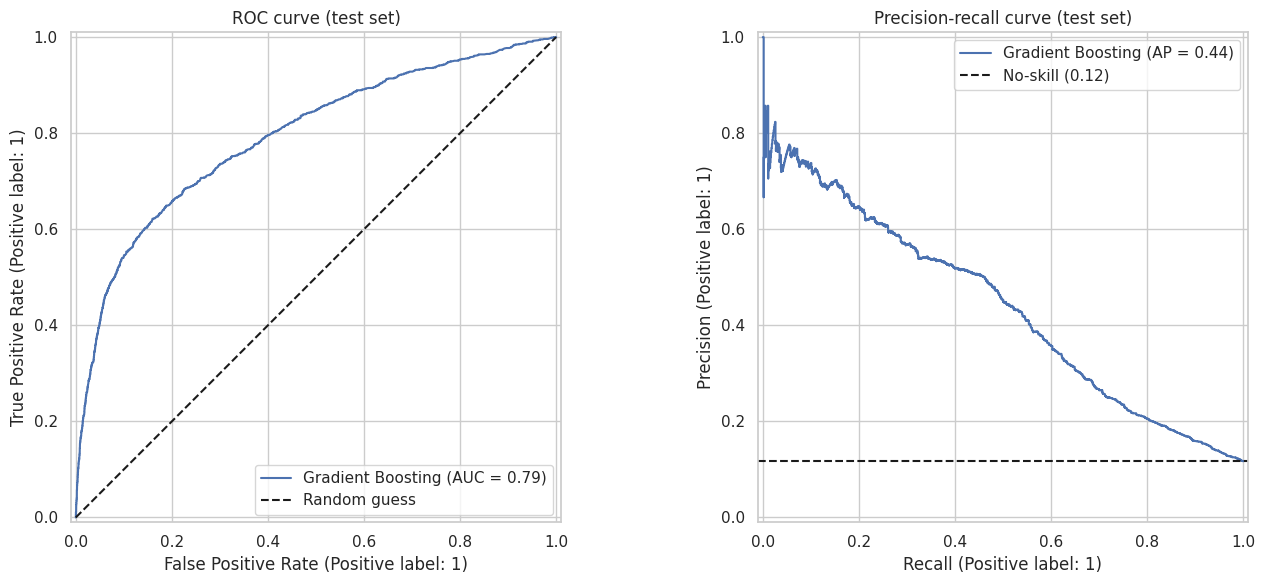

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
RocCurveDisplay.from_estimator(best_model, X_test, y_test, ax=axes[0], name=best_model_name)
axes[0].plot([0, 1], [0, 1], "k--", label="Random guess")
axes[0].set_title("ROC curve (test set)")
axes[0].legend()

PrecisionRecallDisplay.from_estimator(best_model, X_test, y_test, ax=axes[1], name=best_model_name)
baseline_rate = y_test.mean()
axes[1].axhline(baseline_rate, color="k", linestyle="--", label=f"No-skill ({baseline_rate:.2f})")
axes[1].set_title("Precision-recall curve (test set)")
axes[1].legend()
plt.tight_layout()
plt.show()

**What the output tells you:**
- **ROC curve:** the further above the dashed diagonal, the better. Close to the diagonal means the model is barely better than guessing.
- **Precision-recall curve:** the dashed line is the no-skill baseline, equal to the share of subscribers (about 0.12). The curve must stay clearly above it to be useful. A curve that starts high and drops quickly means the model is confident about a few customers only.
- **Which curve to trust:** with a rare positive class, PR-AUC gives a more honest picture than ROC-AUC, because ROC-AUC can look good even when precision is poor.

## 13. Decision-threshold selection
**What this code does:** the default threshold (0.5) is not necessarily best for an imbalanced target. This code:
1. Gets out-of-fold (OOF) scores for the training data, meaning each training customer is scored by a model that did not see them.
2. Finds the threshold that maximises F1 on these OOF scores.
3. Applies that threshold to the test set once, to show its effect.

The test set is never used to pick the threshold.

In [ ]:
oof_scores = cross_val_predict(best_model, X_train, y_train, cv=cv,
                               method=score_method, n_jobs=1)
oof_scores = oof_scores[:, 1] if oof_scores.ndim == 2 else np.asarray(oof_scores).ravel()

precisions, recalls, thresholds = precision_recall_curve(y_train, oof_scores)
f1_curve = 2 * precisions[:-1] * recalls[:-1] / (precisions[:-1] + recalls[:-1] + 1e-12)
selected_threshold = float(thresholds[int(np.nanargmax(f1_curve))])
default_threshold = 0.5 if has_proba else 0.0
print("Default threshold:", default_threshold)
print("Selected threshold (training OOF, max F1):", round(selected_threshold, 4))

plt.figure(figsize=(8, 5))
plt.plot(thresholds, precisions[:-1], label="Precision")
plt.plot(thresholds, recalls[:-1], label="Recall")
plt.axvline(selected_threshold, color="k", linestyle="--", label="Selected threshold")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Training OOF precision and recall by threshold")
plt.legend()
plt.tight_layout()
plt.show()

compare = pd.DataFrame({
    "Metric": ["Precision", "Recall", "F1", "Customers flagged"],
    "Default threshold": [
        precision_score(y_test, test_scores >= default_threshold, zero_division=0),
        recall_score(y_test, test_scores >= default_threshold, zero_division=0),
        f1_score(y_test, test_scores >= default_threshold, zero_division=0),
        int((test_scores >= default_threshold).sum()),
    ],
    "OOF-selected threshold": [
        precision_score(y_test, test_scores >= selected_threshold, zero_division=0),
        recall_score(y_test, test_scores >= selected_threshold, zero_division=0),
        f1_score(y_test, test_scores >= selected_threshold, zero_division=0),
        int((test_scores >= selected_threshold).sum()),
    ],
})
display(compare.round(4))

**What the output tells you:**
- **The plot:** where the precision and recall lines cross is a sensible operating point. The dashed line marks the chosen threshold.
- **Comparison table:** the selected threshold often lifts recall at the cost of some precision. Check the "Customers flagged" row. It tells the campaign team how many calls they would make, which is usually the most useful number for a business.
- **If the two columns are almost identical**, the default threshold was already reasonable, and the extra step adds little.
- The best threshold depends on the cost of a missed subscriber against the cost of a wasted call. The notebook uses F1 as a neutral default. Your report should say the threshold is adjustable.

### 13.1 Probability calibration check
**What this code does:** checks whether the predicted probabilities mean what they say. A calibrated model that gives 0.20 should be right about 20% of the time. The code:
1. Computes the Brier score (lower is better; a model that always predicts the base rate scores about 0.10).
2. Fits a calibrated version (Platt scaling) on the training data and compares its Brier score on the test set.
3. Draws a reliability curve: predicted probability against observed frequency.

This matters if the bank ranks customers by expected value, rather than just flagging a group.

Brier score, raw model:        0.0835
Brier score, calibrated model: 0.083
Brier score, predict the base rate: 0.1033


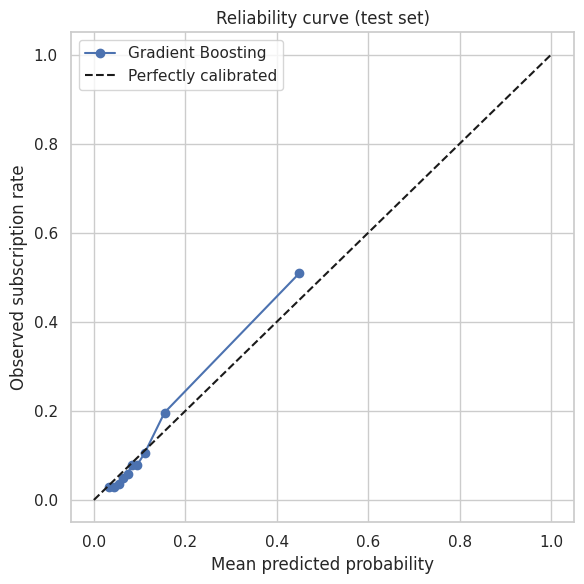

In [ ]:
brier_raw = brier_cal = brier_base = None
if has_proba:
    raw_prob = best_model.predict_proba(X_test)[:, 1]
    calibrated = CalibratedClassifierCV(estimator=best_model, method="sigmoid", cv=3)
    calibrated.fit(X_train, y_train)
    cal_prob = calibrated.predict_proba(X_test)[:, 1]

    print("Brier score, raw model:       ", round(brier_score_loss(y_test, raw_prob), 4))
    print("Brier score, calibrated model:", round(brier_score_loss(y_test, cal_prob), 4))
    print("Brier score, predict the base rate:", round(y_test.mean() * (1 - y_test.mean()), 4))
    brier_raw = brier_score_loss(y_test, raw_prob)
    brier_cal = brier_score_loss(y_test, cal_prob)
    brier_base = y_test.mean() * (1 - y_test.mean())
    if brier_raw > brier_base:
        print("NOTE: the raw probabilities are WORSE than always predicting the base rate. "
              "This is typical when class_weight='balanced' is used: ranking is fine, "
              "but the probabilities are inflated and should not be read as literal chances.")

    frac_pos, mean_pred = calibration_curve(y_test, raw_prob, n_bins=10, strategy="quantile")
    plt.figure(figsize=(6, 6))
    plt.plot(mean_pred, frac_pos, marker="o", label=best_model_name)
    plt.plot([0, 1], [0, 1], "k--", label="Perfectly calibrated")
    plt.xlabel("Mean predicted probability")
    plt.ylabel("Observed subscription rate")
    plt.title("Reliability curve (test set)")
    plt.legend()
    plt.tight_layout()
    plt.show()
else:
    print("This model has no predict_proba, so the calibration check is skipped.")

**What the output tells you:**
- **Brier scores:** the model should beat the "predict the base rate" line (about 0.10). If it does not, its probabilities add little. If the calibrated score is clearly lower than the raw one, calibration helped.
- **Class weights and probabilities:** `class_weight="balanced"` pushes predicted probabilities upward. A raw Brier score worse than the base-rate line therefore does not mean the ranking is bad. It means the probabilities need calibration (the calibrated score) before they are quoted as chances.
- **Reliability curve:** points on the dashed diagonal mean good calibration. Points above the line mean the model is underconfident (it says 0.2 but the true rate is higher). Points below mean it is overconfident.
- If the model is poorly calibrated but ranks customers well, the ranking is still useful. The probabilities should just not be read as literal chances. The threshold chosen in Section 13 still works, because it is based on ranking.

## 14. Model interpretation and feature importance
**What this code does:** for each feature, shuffles its values in the test set, measures how much the model's F1 drops, and repeats five times. A large drop means the model relies on that feature.

It is run **after** the final evaluation and is descriptive only. It must not be used to change the model.

,Feature,Mean drop in F1,Std
0,poutcome,0.2016,0.0045
1,month,0.0359,0.0055
2,housing,0.0311,0.0032
3,day,0.0149,0.0042
4,age,0.0120,0.0041
5,contact,0.0093,0.0042
6,pdays,0.0087,0.0042
7,education,0.0034,0.0024
8,balance,0.0032,0.0027
9,previous,0.0027,0.0011


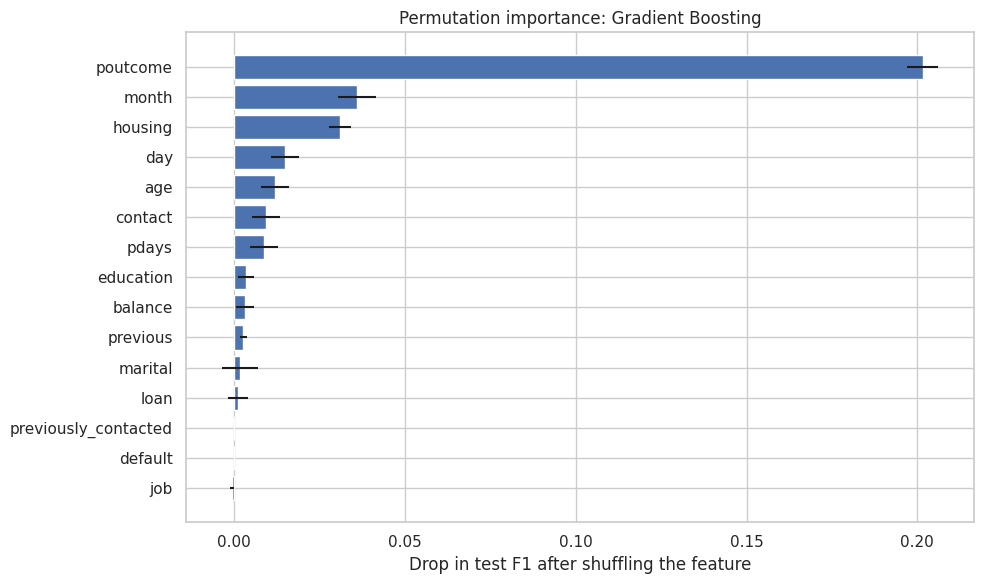

In [ ]:
perm = permutation_importance(best_model, X_test, y_test, n_repeats=5,
                              random_state=RANDOM_STATE, scoring="f1", n_jobs=1)
perm_df = (pd.DataFrame({"Feature": X_test.columns,
                         "Mean drop in F1": perm.importances_mean,
                         "Std": perm.importances_std})
             .sort_values("Mean drop in F1", ascending=False)
             .reset_index(drop=True))
display(perm_df.head(15).round(4))

top = perm_df.head(15).sort_values("Mean drop in F1")
plt.figure(figsize=(10, 6))
plt.barh(top["Feature"], top["Mean drop in F1"], xerr=top["Std"])
plt.xlabel("Drop in test F1 after shuffling the feature")
plt.title(f"Permutation importance: {best_model_name}")
plt.tight_layout()
plt.show()

**What the output tells you:**
- **Top features** are the ones the model depends on. Read the top features from your own output rather than assuming a ranking. Compare them with the subscription rates in Section 4.4 and explain any difference.
- **Negative or near-zero values** mean the feature adds nothing for this model. This is not a problem, but it is worth mentioning.
- **Large std relative to the mean** means the importance is unstable. Treat that feature's rank as uncertain.
- **Important caution:** importance shows predictive reliance, not cause. A feature can be important because it correlates with the real driver.

## 15. Model Export and Reproducibility
**What this code does:** saves everything needed to use the model later into one file: the fitted pipeline, the chosen threshold, the feature column order, and the scoring method. It also writes `requirements.txt` with the exact library versions used, and a short metadata file.

This is what turns a notebook result into something that can be reused.

In [ ]:
from importlib.metadata import version as pkg_version

bundle = {
    "pipeline": best_model,
    "threshold": selected_threshold,
    "score_method": score_method,
    "feature_columns": X.columns.tolist(),
    "raw_columns": RAW_COLUMNS,
    "model_name": best_model_name,
    "random_state": RANDOM_STATE,
}
joblib.dump(bundle, "bank_term_deposit_model.joblib")

packages = ["numpy", "pandas", "scikit-learn", "scipy", "matplotlib", "seaborn", "joblib", "ucimlrepo"]
with open("requirements.txt", "w") as f:
    for p in packages:
        f.write(f"{p}=={pkg_version(p)}\n")

metadata = {"model": best_model_name, "params": {k: str(v) for k, v in best_params.items()},
            "threshold": selected_threshold, "score_method": score_method,
            "train_rows": int(len(X_train)), "test_rows": int(len(X_test)),
            "dataset": "UCI Bank Marketing (id 222)"}
with open("model_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

print("Saved: bank_term_deposit_model.joblib, requirements.txt, model_metadata.json")
print(open("requirements.txt").read())

Saved: bank_term_deposit_model.joblib, requirements.txt, model_metadata.json
numpy==2.4.6
pandas==2.2.3
scikit-learn==1.6.1
scipy==1.16.3
matplotlib==3.10.0
seaborn==0.13.2
joblib==1.6.0
ucimlrepo==0.0.7



**What the output tells you:**
- Three files should appear in the working folder. Check that they exist.
- **requirements.txt** lists exact versions. Anyone who installs these versions should get the same results. Include this file with your submission.
- **The joblib file** holds the model and threshold. If you reload it in a new session, the predictions should match (Section 15.2 checks this).

### 15.1 Demonstration: Prediction for a New Customer
**What this code does:** defines `predict_subscription`, which takes a table of customers and returns a score and a yes/no flag for each one. It:
1. Checks that all required columns are present, and raises a clear error if not.
2. Applies the same `prepare_features` used in training.
3. Aligns the columns to the training order.
4. Scores the customers with the saved pipeline and applies the saved threshold.

It loads the bundle from disk, the way a deployed service would.

In [ ]:
loaded = joblib.load("bank_term_deposit_model.joblib")

def predict_subscription(records: pd.DataFrame, bundle: dict = loaded) -> pd.DataFrame:
    missing = [c for c in bundle["raw_columns"] if c not in records.columns]
    if missing:
        raise ValueError(f"Missing required columns: {missing}")

    X_new = prepare_features(records[bundle["raw_columns"]])
    X_new = X_new.reindex(columns=bundle["feature_columns"])

    if bundle["score_method"] == "predict_proba":
        scores = bundle["pipeline"].predict_proba(X_new)[:, 1]
    else:
        scores = np.asarray(bundle["pipeline"].decision_function(X_new)).ravel()

    return pd.DataFrame({
        "score": np.round(scores, 4),
        "predicted_subscriber": (scores >= bundle["threshold"]).astype(int),
    }, index=records.index)

print("Example: first five customers from the dataset")
display(predict_subscription(data[RAW_COLUMNS].head(5)))

print("Example: a new customer with a job value not seen in training")
new_customer = pd.DataFrame([{
    "age": 40, "job": "astronaut", "marital": "married", "education": "tertiary",
    "default": "no", "balance": 1500, "housing": "yes", "loan": "no",
    "contact": "cellular", "day": 15, "month": "may", "pdays": -1,
    "previous": 0, "poutcome": "unknown",
}])
display(predict_subscription(new_customer))

Example: first five customers from the dataset


,score,predicted_subscriber
0,0.0450,0
1,0.0418,0
2,0.0322,0
3,0.0429,0
4,0.0513,0


Example: a new customer with a job value not seen in training


,score,predicted_subscriber
0,0.0867,0


**What the output tells you:**
- **First table:** each customer has a `score` (a probability or a decision score, depending on the model) and a `predicted_subscriber` of 1 or 0.
- **Second table:** the unseen job `astronaut` should **not** crash the function, because the encoder was set to ignore unknown categories. If it did crash, the encoder setting in Section 7 is wrong.
- **Score meaning:** if `score_method` is `predict_proba`, the score is a probability between 0 and 1. If it is `decision_function`, the score is a distance from the boundary and is not a probability.
- If you pass a table with a missing column, the function should raise the `ValueError` with a readable message. Try this yourself to confirm.

### 15.2 Automated Validation Checks
**What this code does:** runs small tests that fail loudly if an important assumption breaks. These protect against silent mistakes when the notebook is edited later.

Each `assert` is a check. If one is false, Python stops with an error.

In [ ]:
def run_checks():
    checks = {}

    checks["target has only yes/no"] = set(df["deposit"].unique()) == {"yes", "no"}
    checks["no NaN left in categorical columns"] = int(df[cat_in_df].isna().sum().sum()) == 0
    checks["excluded columns absent from predictors"] = not set(EXCLUDED_COLUMNS) & set(X.columns)
    checks["pdays -1 replaced by NaN"] = int(X["pdays"].isna().sum()) == int((data["pdays"] == -1).sum())
    checks["previously_contacted is binary"] = set(X["previously_contacted"].unique()) <= {0, 1}
    checks["training and test rows do not overlap"] = len(set(X_train.index) & set(X_test.index)) == 0
    checks["split keeps class balance (within 1 point)"] = abs(
        y_train.mean() - y_test.mean()) < 0.01
    checks["predictions for unseen category run"] = len(predict_subscription(new_customer)) == 1
    if has_proba:
        p = predict_subscription(data[RAW_COLUMNS].head(50))["score"]
        checks["probabilities lie in [0, 1]"] = bool(((p >= 0) & (p <= 1)).all())
    reloaded = predict_subscription(data[RAW_COLUMNS].head(50))["score"].to_numpy()
    fresh = pd.Series(best_model.predict_proba(prepare_features(data[RAW_COLUMNS].head(50)))[:, 1]
                      if has_proba else best_model.decision_function(
                          prepare_features(data[RAW_COLUMNS].head(50)))).round(4).to_numpy()
    checks["saved model reproduces in-memory scores"] = bool(np.allclose(reloaded, fresh, atol=1e-4))

    for name, ok in checks.items():
        print(("PASS" if ok else "FAIL"), "-", name)
    assert all(checks.values()), "One or more checks failed"
    print("\nAll checks passed.")

run_checks()

PASS - target has only yes/no
PASS - no NaN left in categorical columns
PASS - excluded columns absent from predictors
PASS - pdays -1 replaced by NaN
PASS - previously_contacted is binary
PASS - training and test rows do not overlap
PASS - split keeps class balance (within 1 point)
PASS - predictions for unseen category run
PASS - probabilities lie in [0, 1]
PASS - saved model reproduces in-memory scores

All checks passed.


**What the output tells you:**
- Every line should say **PASS**. Any **FAIL** means that assumption is broken. Do not submit until it is fixed.
- The last check confirms that the saved model gives the same answers as the one in memory. A FAIL here usually means the library versions changed since saving.
- These checks are a good part of the "engineering" section of your report. They show that you thought about failure, not only accuracy.

## 16. Main findings and business interpretation
**What this code does:** prints the key results in one place, so you can copy them into your report. Run it last.

In [ ]:
summary = {
    "Dataset rows (after duplicate removal)": len(data),
    "Predictors used": X.shape[1],
    "Excluded columns": EXCLUDED_COLUMNS,
    "Algorithm at default threshold (Sec. 8)": default_winner,
    "Selected algorithm (best-threshold F1, Sec. 8.1)": baseline_name,
    "Tuned parameters": best_params,
    "Threshold (training OOF)": round(selected_threshold, 4),
}
for key, value in summary.items():
    print(f"{key}: {value}")
print()
display(cv_results[["Algorithm", "f1 mean", "f1 std", "pr_auc mean", "pr_auc std"]].round(4))
display(final_metrics.round(4))
display(fair_results.round(4))


Dataset rows (after duplicate removal): 45211
Predictors used: 15
Excluded columns: ['deposit', 'duration', 'campaign']
Algorithm at default threshold (Sec. 8): Decision Tree
Selected algorithm (best-threshold F1, Sec. 8.1): Gradient Boosting
Tuned parameters: {'classifier__learning_rate': 0.1, 'classifier__max_depth': 2, 'classifier__n_estimators': 120}
Threshold (training OOF): 0.1697



,Algorithm,f1 mean,f1 std,pr_auc mean,pr_auc std
0,Decision Tree,0.4103,0.0244,0.3727,0.0087
1,Gaussian Naive Bayes,0.3873,0.0111,0.3314,0.0056
2,Linear SVM,0.3738,0.0065,0.3887,0.0085
3,Logistic Regression,0.3730,0.0060,0.3940,0.0075
4,Random Forest,0.3100,0.0127,0.4083,0.0152
5,K-Nearest Neighbours,0.2867,0.0139,0.3228,0.0131
6,Gradient Boosting,0.2774,0.0059,0.4239,0.0090


,Algorithm,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Gradient Boosting,0.5,0.8935,0.6667,0.1796,0.2829,0.7934,0.4372


,Algorithm,F1 @ default threshold,Best-threshold F1 (OOF),Threshold,Precision,Recall,PR-AUC (OOF),ROC-AUC (OOF)
0,Gradient Boosting,0.2774,0.4782,0.1599,0.4561,0.5025,0.4216,0.7819
1,Decision Tree,0.4103,0.4443,0.7023,0.4329,0.4564,0.3860,0.7611
2,Random Forest,0.3100,0.4440,0.2440,0.4061,0.4897,0.4069,0.7741
3,Logistic Regression,0.3730,0.4329,0.6515,0.4527,0.4148,0.3930,0.7603
4,Linear SVM,0.3738,0.4305,0.1799,0.3977,0.4692,0.3877,0.7595
5,Gaussian Naive Bayes,0.3873,0.3993,1.0000,0.4757,0.3441,0.3308,0.7360
6,K-Nearest Neighbours,0.2867,0.3837,0.2671,0.3479,0.4278,0.3218,0.7098


**What the output tells you:** this is your results page. Use it to answer four questions in your report:
1. Which algorithm performed best, and is the gap larger than the standard deviation? (From the CV table.)
2. Does the test performance match the CV performance? (From the final metrics.)
3. Does the winner change when every model gets its own threshold (Section 8.1)?
4. What trade-off did the threshold make between finding subscribers and wasting calls? (From Section 13.)
5. Which features matter most, and what are the limits of that interpretation? (From Section 14.)

## 17. Limitations to state in your report
- The data comes from one bank in one period. Results may not transfer to other banks or later campaigns.
- The split is random. A time-based split would be closer to real deployment.
- `duration` and `campaign` are excluded on purpose, so the scores are lower than in studies that include them. This is the correct choice for a pre-call model.
- Class weighting is not applied uniformly across all seven models. Section 8.1 compensates with a per-model threshold, but the training setups are still not identical.
- The per-model thresholds in Section 8.1 are chosen on the same out-of-fold scores they are reported on, so those F1 values are slightly optimistic for every model.
- The tuning search is small, and it covers only the selected algorithm.
- Predicted probabilities from class-weighted models are inflated. Use the calibrated version (Section 13.1) if scores are read as probabilities.
- Feature importance and cluster patterns describe historical associations. They do not prove cause.

## 18. Conclusion
The conclusion below is generated from the variables of this run, so its numbers always match the tables and plots above. Re-run the notebook and it updates itself.

In [ ]:
from IPython.display import Markdown, display

fr = fair_results
top, runner = fr.iloc[0], fr.iloc[1]
pr_top = fr.sort_values("PR-AUC (OOF)", ascending=False).iloc[0]
std_top = cv_results.set_index("Algorithm").loc[top["Algorithm"], "f1 std"]
gap = top["Best-threshold F1 (OOF)"] - runner["Best-threshold F1 (OOF)"]
gap_word = "larger than" if gap > std_top else "not larger than"
imb = 100 * y.mean()

yt = y_test.to_numpy()
def at(thr):
    pred = (test_scores >= thr).astype(int)
    tp = int(((pred == 1) & (yt == 1)).sum()); fp = int(((pred == 1) & (yt == 0)).sum())
    return dict(tp=tp, fp=fp, fn=int((yt == 1).sum()) - tp,
                prec=precision_score(yt, pred, zero_division=0),
                rec=recall_score(yt, pred, zero_division=0),
                f1=f1_score(yt, pred, zero_division=0), flagged=int(pred.sum()))
d, s = at(default_threshold), at(selected_threshold)
base_rate = yt.mean()
roc_t = roc_auc_score(yt, test_scores); pr_t = average_precision_score(yt, test_scores)

tie_note = "" if gap > std_top else ", so the top models are effectively tied and the final choice should also weigh interpretability and speed"
changed = ("The winner changed once every model received its own threshold "
           f"(default-threshold winner: {default_winner}), which suggests that part of the original ranking "
           "reflected class-weight differences rather than the algorithms themselves.") \
          if default_winner != baseline_name else \
          "The same algorithm also won at the default threshold, so the result does not depend on the threshold treatment."

if brier_raw is not None:
    calib = (f"**Calibration.** The raw Brier score is {brier_raw:.4f}, the calibrated score is {brier_cal:.4f} "
             f"and the base-rate reference is {brier_base:.4f}. "
             + ("The raw probabilities are worse than the base-rate guess, so they should not be quoted as literal chances; "
                "the ranking is still usable, and the calibrated version fixes the probabilities."
                if brier_raw > brier_base else
                "The raw probabilities already beat the base-rate guess."))
else:
    calib = "**Calibration.** The selected model has no probability output, so calibration was skipped."

pr_note = ("" if pr_top["Algorithm"] == top["Algorithm"] else
           f" {pr_top['Algorithm']} has the best threshold-free ranking (PR-AUC {pr_top['PR-AUC (OOF)']:.3f}), "
           "so the choice of metric changes the preferred model.")

text = f"""
This project compared seven classification algorithms for predicting whether a bank client subscribes to a term deposit, using the UCI Bank Marketing data and only predictors available before the call. About {imb:.0f}% of clients subscribe, so models were compared with F1 (including a tuned threshold per model), PR-AUC and ROC-AUC rather than accuracy.

**Cross-validation.** At each model's own best threshold, **{top['Algorithm']}** had the highest F1 ({top['Best-threshold F1 (OOF)']:.3f}), ahead of {runner['Algorithm']} ({runner['Best-threshold F1 (OOF)']:.3f}). The gap ({gap:.3f}) is {gap_word} the fold-to-fold F1 standard deviation (about {std_top:.3f}){tie_note}.{pr_note} {changed}

**Held-out test set ({best_model_name}).** At the default threshold the test F1 is {d['f1']:.3f} (precision {d['prec']:.3f}, recall {d['rec']:.3f}); at the training-selected threshold ({selected_threshold:.3f}) it is {s['f1']:.3f} (precision {s['prec']:.3f}, recall {s['rec']:.3f}). Test ROC-AUC is {roc_t:.3f} and PR-AUC is {pr_t:.3f}. Compare these with the cross-validation figures in Section 8.1: a large drop would indicate overfitting.

**Error trade-off at the selected threshold.** Of {int((yt == 1).sum()):,} actual subscribers in the test set the model finds {s['tp']:,} and misses {s['fn']:,} (recall {s['rec']:.1%}), and it flags {s['fp']:,} clients who did not subscribe. A missed subscriber is lost revenue; a false positive is one wasted call. If calls are cheap the bank should lower the threshold; if they are expensive it should raise it.

**Practical value.** {s['prec']:.1%} of flagged clients subscribe, against a base rate of {base_rate:.1%}, a lift of about {s['prec'] / base_rate:.1f}x over calling at random. The model supports targeting but does not replace judgement.

{calib}

**Limitations.** One Portuguese bank in one period; a random rather than time-based split; `duration` and `campaign` excluded on purpose; class weights not applied identically to all models (partly offset by per-model thresholds, which are slightly optimistic because they are picked on the out-of-fold scores they are reported on); a small tuning search; and feature importance shows reliance, not cause.

**Which model to prefer.** {top['Algorithm']} is preferred on the primary metric (best-threshold F1). If ranking quality matters most and interpretability matters less, use the PR-AUC leader ({pr_top['Algorithm']}). If probabilities are quoted as chances, use the calibrated version.
"""
display(Markdown(text))


This project compared seven classification algorithms for predicting whether a bank client subscribes to a term deposit, using the UCI Bank Marketing data and only predictors available before the call. About 12% of clients subscribe, so models were compared with F1 (including a tuned threshold per model), PR-AUC and ROC-AUC rather than accuracy.

**Cross-validation.** At each model's own best threshold, **Gradient Boosting** had the highest F1 (0.478), ahead of Decision Tree (0.444). The gap (0.034) is larger than the fold-to-fold F1 standard deviation (about 0.006). The winner changed once every model received its own threshold (default-threshold winner: Decision Tree), which suggests that part of the original ranking reflected class-weight differences rather than the algorithms themselves.

**Held-out test set (Gradient Boosting).** At the default threshold the test F1 is 0.283 (precision 0.667, recall 0.180); at the training-selected threshold (0.170) it is 0.475 (precision 0.456, recall 0.496). Test ROC-AUC is 0.793 and PR-AUC is 0.437. Compare these with the cross-validation figures in Section 8.1: a large drop would indicate overfitting.

**Error trade-off at the selected threshold.** Of 1,058 actual subscribers in the test set the model finds 525 and misses 533 (recall 49.6%), and it flags 626 clients who did not subscribe. A missed subscriber is lost revenue; a false positive is one wasted call. If calls are cheap the bank should lower the threshold; if they are expensive it should raise it.

**Practical value.** 45.6% of flagged clients subscribe, against a base rate of 11.7%, a lift of about 3.9x over calling at random. The model supports targeting but does not replace judgement.

**Calibration.** The raw Brier score is 0.0835, the calibrated score is 0.0830 and the base-rate reference is 0.1033. The raw probabilities already beat the base-rate guess.

**Limitations.** One Portuguese bank in one period; a random rather than time-based split; `duration` and `campaign` excluded on purpose; class weights not applied identically to all models (partly offset by per-model thresholds, which are slightly optimistic because they are picked on the out-of-fold scores they are reported on); a small tuning search; and feature importance shows reliance, not cause.

**Which model to prefer.** Gradient Boosting is preferred on the primary metric (best-threshold F1). If ranking quality matters most and interpretability matters less, use the PR-AUC leader (Gradient Boosting). If probabilities are quoted as chances, use the calibrated version.


## 19. References

1. Moro, S., Rita, P., & Cortez, P. (2014). *Bank Marketing*. UCI Machine Learning Repository. https://doi.org/10.24432/C5K306  
2. UCI Machine Learning Repository. *Bank Marketing dataset documentation*. https://archive.ics.uci.edu/dataset/222/bank+marketing  
3. Pedregosa, F., et al. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830. https://jmlr.org/papers/v12/pedregosa11a.html  
4. Scikit-learn documentation. *Pipeline and composite estimators*. https://scikit-learn.org/stable/modules/compose.html  
5. Scikit-learn documentation. *Model evaluation: quantifying the quality of predictions*. https://scikit-learn.org/stable/modules/model_evaluation.html

Add any additional research papers, articles or documentation actually consulted by the group.